# Customer Segmentation & Retention Analysis

## tl;dr
This portfolio analysis uses UCI Online Retail transaction data to identify valuable customer segments, monitor repeat behavior, and reveal cohort-retention patterns. Run `PYTHONPATH=. python scripts/build_outputs.py` before opening this notebook.

## Context & Methods

**Source:** UCI Online Retail (UK-based online retailer, 1 Dec 2010–9 Dec 2011).

Valid purchase records have a known customer ID, positive quantity and unit price, and an invoice not beginning with `C`. RFM uses days since latest purchase, distinct invoices, and positive revenue. Customer cohorts are based on first-purchase month.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.analysis import build_kpis

data_dir = ROOT / 'data' / 'processed'
transactions = pd.read_csv(data_dir / 'transactions_clean.csv', parse_dates=['InvoiceDate'])
rfm = pd.read_csv(data_dir / 'customer_rfm.csv')
monthly = pd.read_csv(data_dir / 'monthly_revenue.csv', parse_dates=['Month'])
retention = pd.read_csv(data_dir / 'cohort_retention.csv', index_col=0)
metrics = build_kpis(transactions)
metrics

{'customers': 4338,
 'revenue': 8911407.9,
 'orders': 18532,
 'repeat_buyers': 2845,
 'repeat_buyer_rate': 0.6558321807284463}

## Results

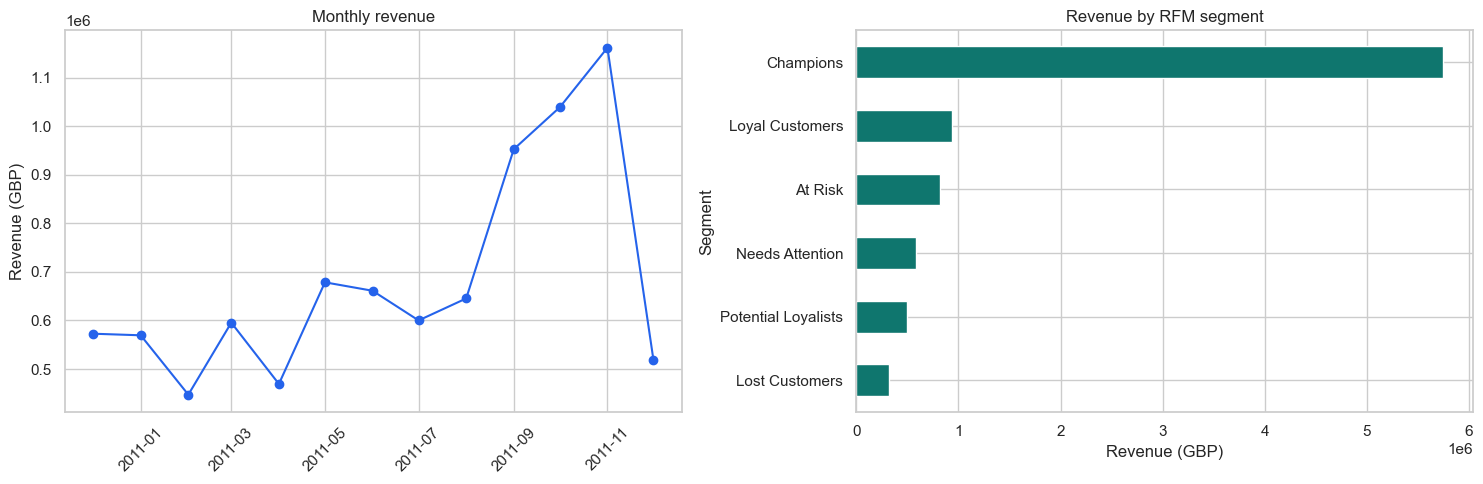

In [2]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(monthly['Month'], monthly['Revenue'], marker='o', color='#2563eb')
axes[0].set_title('Monthly revenue')
axes[0].set_ylabel('Revenue (GBP)')
axes[0].tick_params(axis='x', rotation=45)
segment_value = rfm.groupby('Segment')['Monetary'].sum().sort_values()
segment_value.plot.barh(ax=axes[1], color='#0f766e')
axes[1].set_title('Revenue by RFM segment')
axes[1].set_xlabel('Revenue (GBP)')
plt.tight_layout()
plt.show()

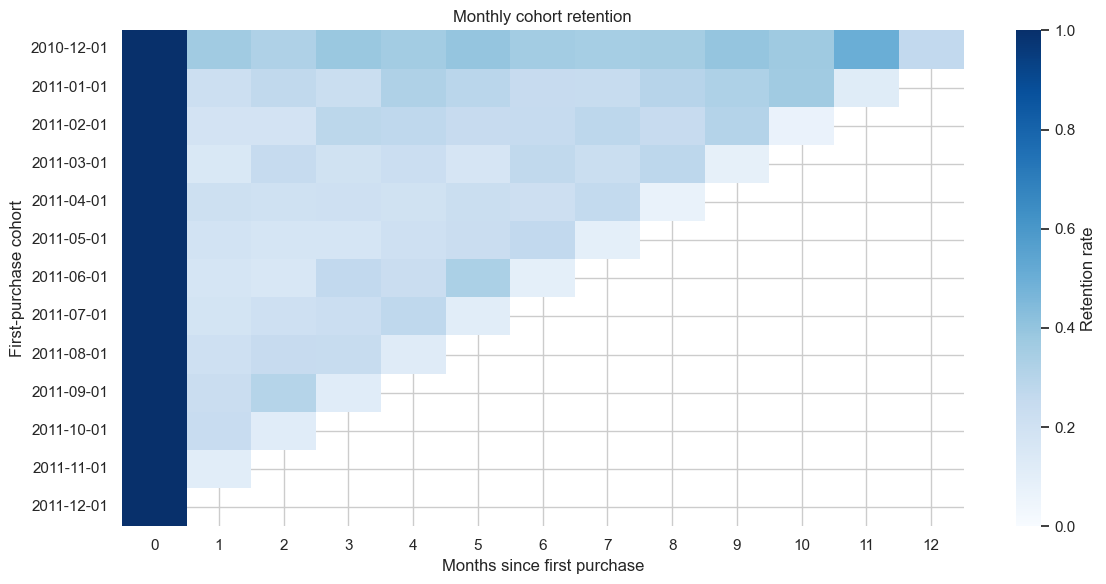

In [3]:
plt.figure(figsize=(12, 6))
sns.heatmap(retention, cmap='Blues', vmin=0, vmax=1, mask=retention.isna(), cbar_kws={'label':'Retention rate'})
plt.title('Monthly cohort retention')
plt.xlabel('Months since first purchase')
plt.ylabel('First-purchase cohort')
plt.tight_layout()
plt.show()

## Takeaways

- **Champions** are the highest-value group and should receive loyalty/VIP treatment.
- **At Risk** customers previously ordered frequently but have become inactive, making them a practical priority for re-engagement.
- The cohort heatmap separates normal early churn from sustained customer retention and keeps future cohort periods blank rather than incorrectly labeling them zero.

For interactive filtering by country and customer segment, run `streamlit run app/dashboard.py`.